In [104]:
# Se necessario, installa le librerie da una cella Jupyter:
# %pip install pandas numpy matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("Hello this is MY-Dashboard - Portfolio! It contains statistical methods for describe accountment and crypto_value transactions")

Hello this is MY-Dashboard - Portfolio! It contains statistical methods for describe accountment and crypto_value transactions


# – Ordinary Accounting e Crypto Notebook
Accounting Analytics
BOOKKEEPING • FINANCIAL REPORTING • TAX ACCOUNTING
Revenue
VAT
Cash Flow
Ordinary Accounting – Statistical Dashboard
THREE CORE ACCOUNTING INDICATORS
01. Economic Result
\(Profit=Revenue-Expenses\)Grouped Bar Chart + Line Chart



02. VAT Position
\(Net\ VAT=VAT_{Debit}-VAT_{Credit}\)Grouped Bar Chart + Line Chart



03. Cash Flow
\(Cash\ Flow=Inflows-Outflows\)

1	profit	\(Profit=Revenue-Expenses\)

2   VAT	\(VAT_{net}=VAT_{debit}-VAT_{credit}\)

3	Cash Flow	\(CF=Inflows-Outflows\)

4	Balance	\(Balance_t=Balance_{t-1}+Inflows_t-Outflows_t\)

*********************************************************************************************************************************************

# Cryptocurrency Accounting


1	Gross Transaction Value	\(G=Q\times P\)

2	Net Purchase Cost	\(Cost=G+Fees\)

3	Net Sale Proceeds	\(Proceeds=G-Fees\)

4	FIFO Cost Basis	\(Cost_{FIFO}=\sum_{i=1}^{n}Q_iP_i\)

5	Realized Gain/Loss	\(P\&L=Net\ Proceeds-Cost_{FIFO}\)

6	Market Value	\(MV=Quantity\times Current\ Price\)

7	Portfolio Allocation	\(w_i=\frac{MV_i}{\sum MV_i}\times100\)


# Financial & Statistical Analysis

1	Daily Returns	\(R_t=\frac{P_t-P_{t-1}}{P_{t-1}}\)

2	Arithmetic Mean	\(\bar R=\frac{1}{n}\sum_{i=1}^{n}R_i\)

3	Variance	\(s^2=\frac{\sum(R_i-\bar R)^2}{n-1}\)

4	Standard Deviation	\(s=\sqrt{s^2}\)

5	Annualized Volatility	\(\sigma_a=\sigma_d\sqrt{365}\)

6	Correlation	\(\rho_{XY}=\frac{Cov(X,Y)}{\sigma_X\sigma_Y}\)

7	Portfolio Return	\(R_p=\sum_{i=1}^{N}w_iR_i\)

8	Cumulative Return	\(CR_t=\prod_{i=1}^{t}(1+R_i)-1\)

9	Portfolio Value	\(V_t=V_0\prod_{i=1}^{t}(1+R_{p,i})\)

10	Sharpe Ratio	\(S_a=\frac{\bar R_p-r_f/365}{\sigma_p}\sqrt{365}\)

11	Drawdown	\(DD_t=\frac{V_t}{\max_{s\leq t}V_s}-1\)

12	Maximum Drawdown	\(MDD=\min_t(DD_t)\)

13	Historical VaR 95%	\(VaR_{95}=-Q_{0.05}(R_p)\)

14	Expected Shortfall 95%	\(ES_{95}=-E[R_p\mid R_p\leq Q_{0.05}]\)

15	Covariance	\(Cov(X,Y)=\frac{\sum(X_i-\bar X)(Y_i-\bar Y)}{n-1}\)

********************************************************************************************************************************************

VAT Credit vs VAT Debit – Grouped Bar Chart

In [92]:
vat = pd.DataFrame({
    "month": [
        "January",
        "January",
        "February",
        "February",
        "March",
        "March"
    ],

    "type": [
        "VAT Debit",
        "VAT Credit",
        "VAT Debit",
        "VAT Credit",
        "VAT Debit",
        "VAT Credit"
    ],

    "amount": [
        1200, 700,
        1500, 900,
        1800, 1100
    ]
})

vat_summary = vat.pivot_table(
    index="month",
    columns="type",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

vat_summary["Net VAT"] = (
    vat_summary["VAT Debit"]
    - vat_summary["VAT Credit"]
)

display(vat_summary)

type,VAT Credit,VAT Debit,Net VAT
month,,,
February,900,1500,600
January,700,1200,500
March,1100,1800,700


# Cash Flow
Questa formula analizza entrate e uscite monetarie.
\[
Cash\ Flow=Incassi-Pagamenti
\]

Esempio:
Movimento	Importo
Incassi clienti	8.000 €
Pagamenti fornitori	3.000 €
Altre uscite	1.000 €
Cash Flow netto	4.000 €

In [93]:
cash = pd.DataFrame({
    "date": [
        "2026-01-05",
        "2026-01-15",
        "2026-02-05",
        "2026-02-15",
        "2026-03-05",
        "2026-03-15"
    ],

    "type": [
        "Inflow",
        "Outflow",
        "Inflow",
        "Outflow",
        "Inflow",
        "Outflow"
    ],

    "amount": [
        8000, 3000,
        9000, 4000,
        10000, 5000
    ]
})

cash["date"] = pd.to_datetime(cash["date"])

cash["month"] = cash["date"].dt.to_period("M")

cash_summary = cash.pivot_table(
    index="month",
    columns="type",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

cash_summary["Net Cash Flow"] = (
    cash_summary["Inflow"]
    - cash_summary["Outflow"]
)

display(cash_summary)

type,Inflow,Outflow,Net Cash Flow
month,,,
2026-01,8000,3000,5000
2026-02,9000,4000,5000
2026-03,10000,5000,5000


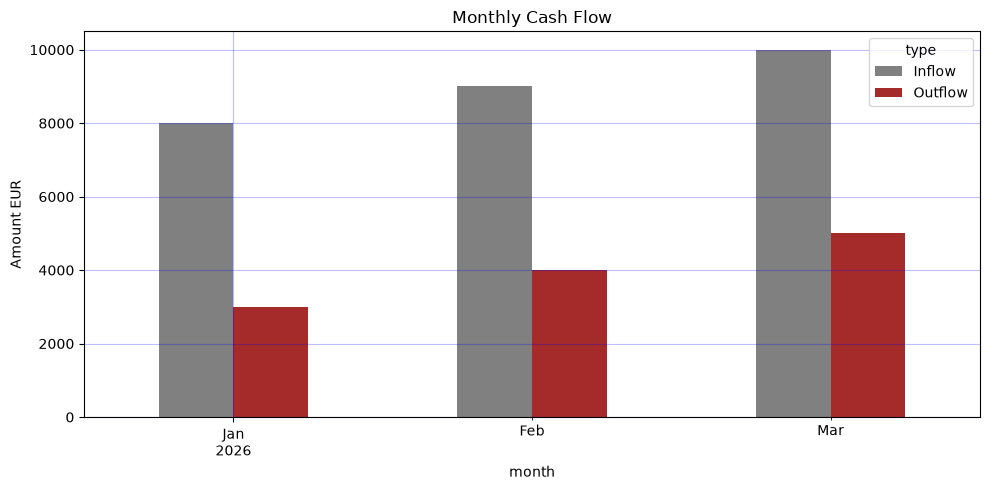

In [94]:
cash_summary[
    ["Inflow", "Outflow"]
].plot(
    kind="bar",
    figsize=(10, 5),
    title="Monthly Cash Flow",
    color=["grey","brown"]
    
)
plt.grid(color="blue")

plt.ylabel("Amount EUR")
plt.tight_layout()
plt.show()

In [95]:
transaction=pd.DataFrame([
    ["2026-01-05", "TX001", "BUY",      "BTC", 0.0200,  42000,  5.00, "Exchange", "Acquisto BTC"],
    ["2026-01-12", "TX002", "BUY",      "ETH", 0.5000,   2800,  3.00, "Exchange", "Acquisto ETH"],
    ["2026-01-20", "TX003", "P2P_BUY",  "BTC", 0.0100,  43500,  2.00, "P2P",      "Acquisto BTC P2P"],
    ["2026-02-03", "TX004", "BUY",      "BTC", 0.0150,  45000,  4.00, "Exchange", "Acquisto BTC"],
    ["2026-02-10", "TX005", "SELL",     "BTC", 0.0120,  48000,  3.50, "Exchange", "Vendita BTC"],
    ["2026-02-18", "TX006", "P2P_SELL", "ETH", 0.1000,   3100,  2.00, "P2P",      "Vendita ETH P2P"],
    ["2026-03-02", "TX007", "BUY",      "ETH", 0.3000,   2950,  2.50, "Exchange", "Acquisto ETH"],
    ["2026-03-11", "TX008", "SELL",     "ETH", 0.1500,   3300,  3.00, "Exchange", "Vendita ETH"],
    ["2026-03-15", "TX009", "FEE",      "BTC", 0.0000,      0,  1.50, "Exchange", "Commissione separata"],
    ["2026-03-20", "TX010", "TRANSFER", "BTC", 0.0050,      0,  0.00, "Wallet",   "Trasferimento tra wallet"]
],columns=["date","id_transaction","mode","asset","n","price-EU","fee","channel", "description"])

transactions=pd.DataFrame(transaction,columns=columns)
transactions=transaction.copy()
display(transactions)

,date,id_transaction,mode,asset,n,price-EU,fee,channel,description
0,2026-01-05,TX001,BUY,BTC,0.020,42000,5.0,Exchange,Acquisto BTC
1,2026-01-12,TX002,BUY,ETH,0.500,2800,3.0,Exchange,Acquisto ETH
2,2026-01-20,TX003,P2P_BUY,BTC,0.010,43500,2.0,P2P,Acquisto BTC P2P
3,2026-02-03,TX004,BUY,BTC,0.015,45000,4.0,Exchange,Acquisto BTC
4,2026-02-10,TX005,SELL,BTC,0.012,48000,3.5,Exchange,Vendita BTC
5,2026-02-18,TX006,P2P_SELL,ETH,0.100,3100,2.0,P2P,Vendita ETH P2P
6,2026-03-02,TX007,BUY,ETH,0.300,2950,2.5,Exchange,Acquisto ETH
7,2026-03-11,TX008,SELL,ETH,0.150,3300,3.0,Exchange,Vendita ETH
8,2026-03-15,TX009,FEE,BTC,0.000,0,1.5,Exchange,Commissione separata
9,2026-03-20,TX010,TRANSFER,BTC,0.005,0,0.0,Wallet,Trasferimento tra wallet


In [96]:
transaction["date"]=pd.to_datetime(transaction["date"])
transaction["gross_EU"]=pd.to_numeric(transaction["n"]*transaction["price-EU"])
transactions=transaction.copy()
display(transactions)

,date,id_transaction,mode,asset,n,price-EU,fee,channel,description,gross_EU
0,2026-01-05,TX001,BUY,BTC,0.020,42000,5.0,Exchange,Acquisto BTC,840.0
1,2026-01-12,TX002,BUY,ETH,0.500,2800,3.0,Exchange,Acquisto ETH,1400.0
2,2026-01-20,TX003,P2P_BUY,BTC,0.010,43500,2.0,P2P,Acquisto BTC P2P,435.0
3,2026-02-03,TX004,BUY,BTC,0.015,45000,4.0,Exchange,Acquisto BTC,675.0
4,2026-02-10,TX005,SELL,BTC,0.012,48000,3.5,Exchange,Vendita BTC,576.0
5,2026-02-18,TX006,P2P_SELL,ETH,0.100,3100,2.0,P2P,Vendita ETH P2P,310.0
6,2026-03-02,TX007,BUY,ETH,0.300,2950,2.5,Exchange,Acquisto ETH,885.0
7,2026-03-11,TX008,SELL,ETH,0.150,3300,3.0,Exchange,Vendita ETH,495.0
8,2026-03-15,TX009,FEE,BTC,0.000,0,1.5,Exchange,Commissione separata,0.0
9,2026-03-20,TX010,TRANSFER,BTC,0.005,0,0.0,Wallet,Trasferimento tra wallet,0.0


#p2p transactions

In [97]:
conditions=[transactions["mode"].isin(["BUY","P2P"]),transactions["mode"].isin(["SELL","P2P"])]

chois=[transactions["gross_EU"]+transactions["fee"],
         transactions["gross_EU"]-transactions["fee"]]

transactions["Net_EU"]=np.select(conditions,chois,default=0.0)
display(transactions)

,date,id_transaction,mode,asset,n,price-EU,fee,channel,description,gross_EU,Net_EU
0,2026-01-05,TX001,BUY,BTC,0.020,42000,5.0,Exchange,Acquisto BTC,840.0,845.0
1,2026-01-12,TX002,BUY,ETH,0.500,2800,3.0,Exchange,Acquisto ETH,1400.0,1403.0
2,2026-01-20,TX003,P2P_BUY,BTC,0.010,43500,2.0,P2P,Acquisto BTC P2P,435.0,0.0
3,2026-02-03,TX004,BUY,BTC,0.015,45000,4.0,Exchange,Acquisto BTC,675.0,679.0
4,2026-02-10,TX005,SELL,BTC,0.012,48000,3.5,Exchange,Vendita BTC,576.0,572.5
5,2026-02-18,TX006,P2P_SELL,ETH,0.100,3100,2.0,P2P,Vendita ETH P2P,310.0,0.0
6,2026-03-02,TX007,BUY,ETH,0.300,2950,2.5,Exchange,Acquisto ETH,885.0,887.5
7,2026-03-11,TX008,SELL,ETH,0.150,3300,3.0,Exchange,Vendita ETH,495.0,492.0
8,2026-03-15,TX009,FEE,BTC,0.000,0,1.5,Exchange,Commissione separata,0.0,0.0
9,2026-03-20,TX010,TRANSFER,BTC,0.005,0,0.0,Wallet,Trasferimento tra wallet,0.0,0.0


In [98]:
def class_transaction(type):
    if type=="BUY": return "v"
    else: return "-"
transactions["description"]=(transactions["mode"].apply(class_transaction))
display(transactions)

,date,id_transaction,mode,asset,n,price-EU,fee,channel,description,gross_EU,Net_EU
0,2026-01-05,TX001,BUY,BTC,0.020,42000,5.0,Exchange,v,840.0,845.0
1,2026-01-12,TX002,BUY,ETH,0.500,2800,3.0,Exchange,v,1400.0,1403.0
2,2026-01-20,TX003,P2P_BUY,BTC,0.010,43500,2.0,P2P,-,435.0,0.0
3,2026-02-03,TX004,BUY,BTC,0.015,45000,4.0,Exchange,v,675.0,679.0
4,2026-02-10,TX005,SELL,BTC,0.012,48000,3.5,Exchange,-,576.0,572.5
5,2026-02-18,TX006,P2P_SELL,ETH,0.100,3100,2.0,P2P,-,310.0,0.0
6,2026-03-02,TX007,BUY,ETH,0.300,2950,2.5,Exchange,v,885.0,887.5
7,2026-03-11,TX008,SELL,ETH,0.150,3300,3.0,Exchange,-,495.0,492.0
8,2026-03-15,TX009,FEE,BTC,0.000,0,1.5,Exchange,-,0.0,0.0
9,2026-03-20,TX010,TRANSFER,BTC,0.005,0,0.0,Wallet,-,0.0,0.0


In [99]:
rng=np.random.default_rng(42)
dates=pd.date_range(start="2026-11-16",periods=120,freq="D")
returns=pd.DataFrame({
    "BTC":rng.normal(0.001,0.025,len(dates)),
    "ETH":rng.normal(0.0012,0.032,len(dates))
},index=dates)
price=pd.DataFrame(index=dates)
price["BTC"]=(
    42000*(1+returns["BTC"]).cumprod())
price["ETH"]=(
    2800*(1+returns["ETH"]).cumprod())
display(price.head())


,BTC,ETH
2026-11-16,42361.952934,2711.654625
2026-11-17,41302.920943,2730.464886
2026-11-18,42119.119524,2752.963626
2026-11-19,43151.632586,2876.004589
2026-11-20,41090.025378,2956.312876


# Daily Returns 
Rt=(Pt/Pt-1)-1

,BTC,ETH
2026-11-17,-0.025000,0.006937
2026-11-18,0.019761,0.008240
2026-11-19,0.024514,0.044694
2026-11-20,-0.047776,0.027924
2026-11-21,-0.031554,0.012620


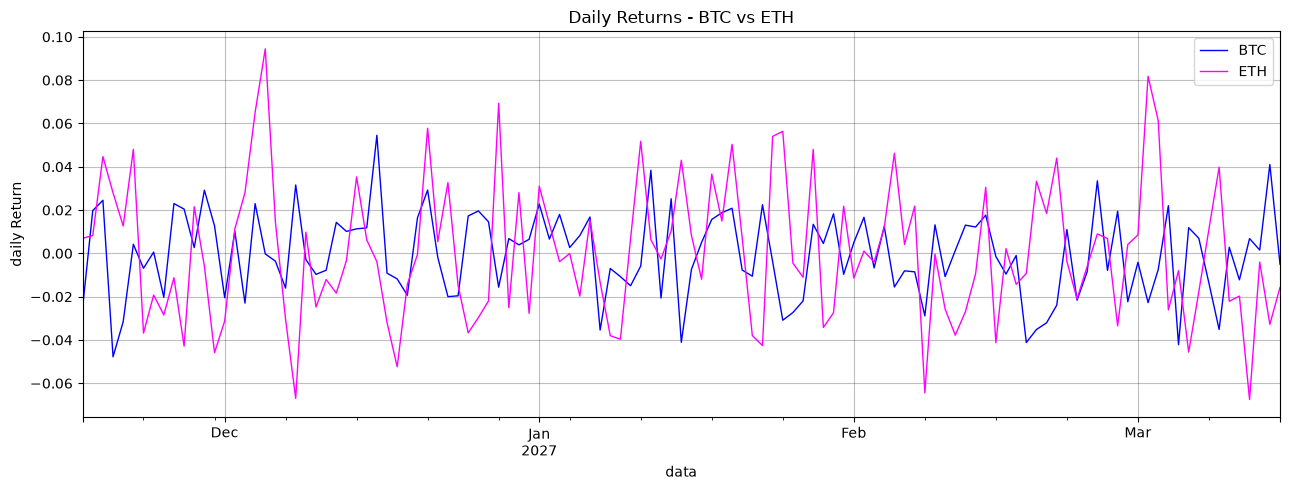

In [100]:
dreturns=price.pct_change().dropna()
display(dreturns.head())
dreturns.plot(figsize=(13,5),color=["blue","magenta"],title="Daily Returns - BTC vs ETH",linewidth=1)
plt.xlabel("data")
plt.ylabel("daily Return")
plt.grid(color="black")
plt.tight_layout()
plt.show()

# Annualized Volatility
Oa=sqrt(365*Od)

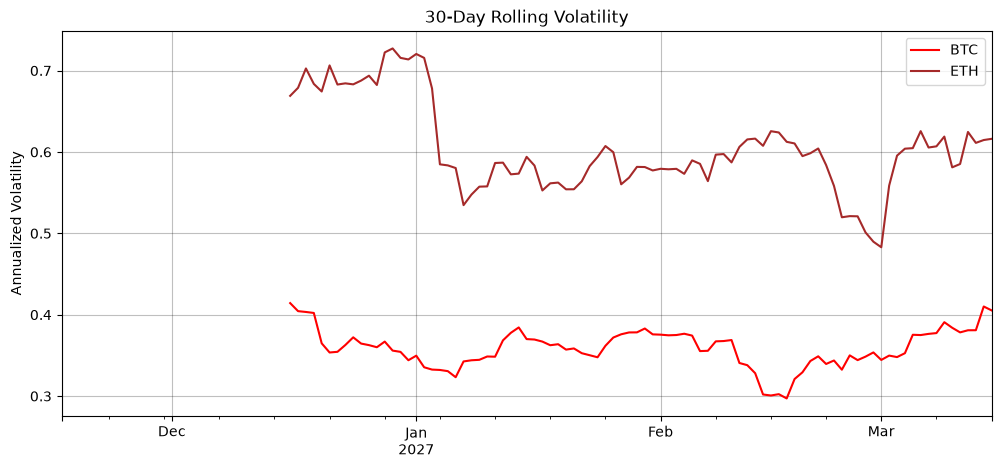

In [101]:
rolling_volatility = (
    dreturns.rolling(window=30).std()
    * np.sqrt(365)
)

rolling_volatility.plot(
    figsize=(12, 5),
    title="30-Day Rolling Volatility",
    color=["red","brown"]
)
plt.grid(color="black")
plt.ylabel("Annualized Volatility")
plt.show()

# Correlation Headmap 
P=Cov(BTC,ETH)/oBTC*oETC

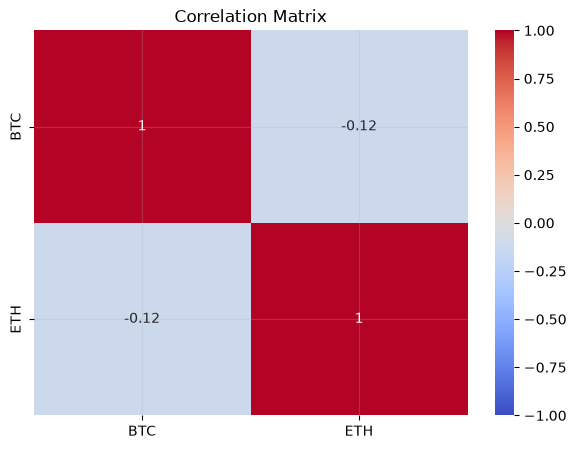

In [102]:
import seaborn as sns

correlation = dreturns.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.show()

In [106]:
transactions.to_csv("crypto_transactions_demo.csv", index=False)
print("File CSV is in notebook")

File CSV is in notebook
